In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

In [2]:
df=pd.read_csv('../Datasets/vgsales.csv')
df

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...,...
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002.0,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16594,16597,Men in Black II: Alien Escape,GC,2003.0,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008.0,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16596,16599,Know How 2,DS,2010.0,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


# Data Priparation

In [3]:
df.dtypes

Rank              int64
Name             object
Platform         object
Year            float64
Genre            object
Publisher        object
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object

# Use Pandas to inspect missing values

In [4]:
df.isnull().sum()

Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

In [5]:
df.Year=df.Year.fillna(0)
df.Publisher=df.Publisher.fillna(0)
df.dtypes

Rank              int64
Name             object
Platform         object
Year            float64
Genre            object
Publisher        object
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object

In [6]:
df["Year"]=pd.to_datetime(df["Year"])

# Exploratory Data Analysis (EDA):

In [7]:
df.describe()

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16598,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
mean,8300.605254,1970-01-01 00:00:00.000001973,0.264667,0.146652,0.077782,0.048063,0.537441
min,1.000000,1970-01-01 00:00:00,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,1970-01-01 00:00:00.000002003,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,1970-01-01 00:00:00.000002007,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,1970-01-01 00:00:00.000002010,0.240000,0.110000,0.040000,0.040000,0.470000
max,16600.000000,1970-01-01 00:00:00.000002020,41.490000,29.020000,10.220000,10.570000,82.740000
std,4791.853933,NaN,0.816683,0.505351,0.309291,0.188588,1.555028


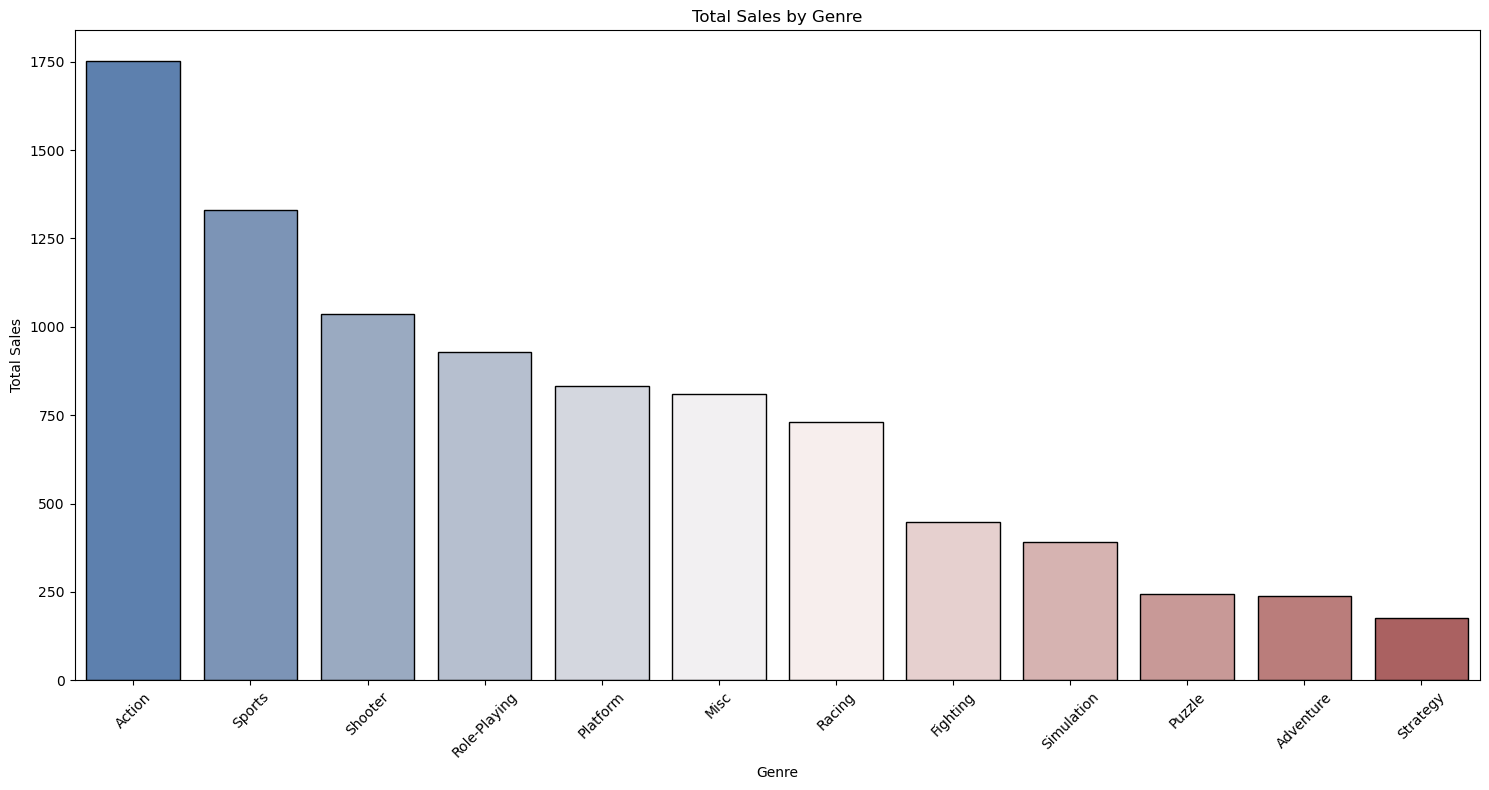

In [25]:
genre_sales = df.groupby("Genre")["Global_Sales"].agg(Total_Sales="sum", Average_Sales="mean").sort_values("Total_Sales", ascending=False)
plt.figure(figsize=(15, 8))
sb.barplot(x=genre_sales.index,y=genre_sales["Total_Sales"],hue=genre_sales.index,palette="vlag",edgecolor="black")
plt.xticks(rotation=45)
plt.title("Total Sales by Genre")
plt.ylabel("Total Sales")
plt.xlabel("Genre")
plt.tight_layout()
plt.show()

# Outcome:

### 1. Action games recorded the highest total sales of 1,751.18 million copies, followed by Sports games at 1,330.93 million, showing strong overall demand for these genres.
### 2. Platform games had the highest average sales per game at 0.938 million copies, while Adventure games averaged only 0.186 million, indicating that Platform games sold more per title on average.¶

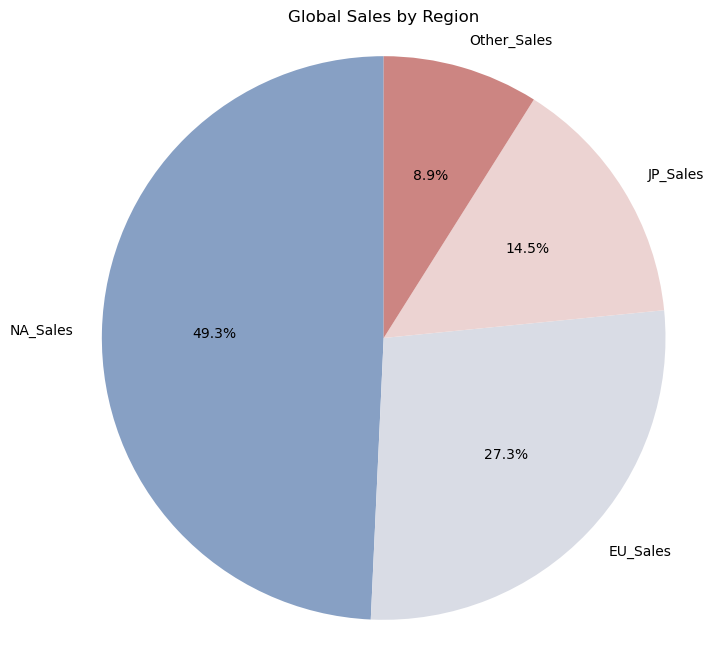

In [26]:
regional_sales=df[["NA_Sales","EU_Sales","JP_Sales","Other_Sales"]].sum()
regional_sales.nlargest(5)
colors = sb.color_palette("vlag", n_colors=len(regional_sales)).as_hex()
plt.figure(figsize=(8, 8))
plt.pie(regional_sales.to_numpy(),labels=regional_sales.index,colors=colors,autopct="%1.1f%%", startangle=90)
plt.title("Global Sales by Region")
plt.axis("equal")
plt.show()

# Outcome
### 1. North America recorded the highest total sales at 4,392.95 million copies, followed by Europe at 2,434.13 million, showing that North America was the strongest market in the dataset.
### 2. North America also had the highest average sales per game at 0.265 million copies, compared with Japan at 0.078 million, indicating stronger average game sales in North America.¶

# Top Selling Games Analysis:

## *What are the top-selling games based on global sales revenue

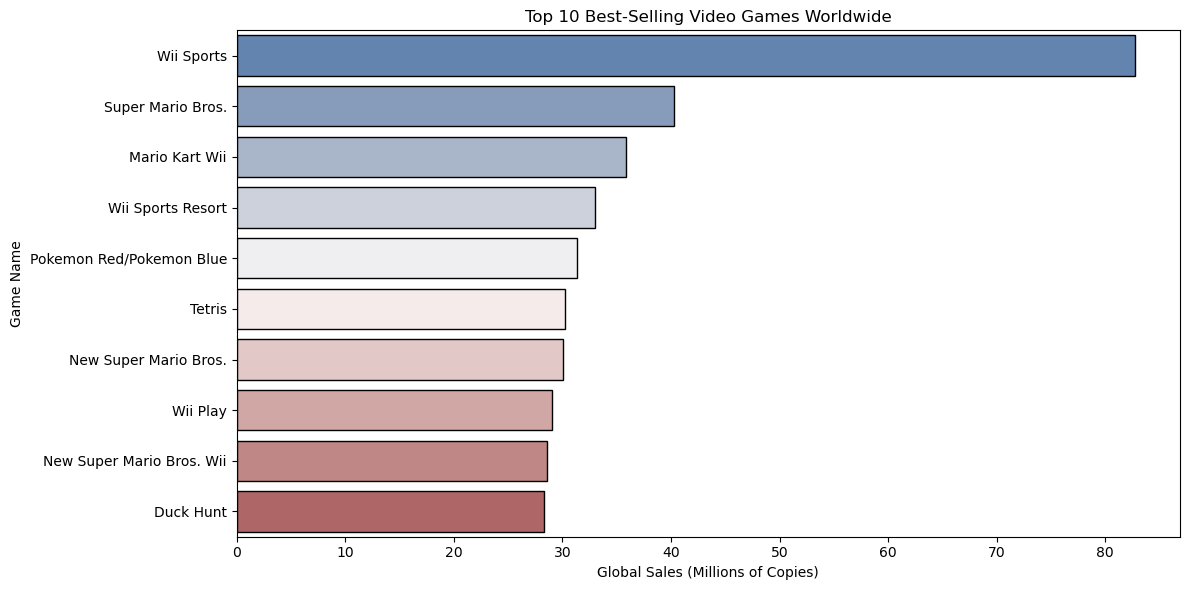

In [27]:
top_selling_games=df.sort_values("Global_Sales",ascending=False)
top_selling_games[["Name","Platform","Global_Sales"]].head(10)
plt.figure(figsize=(12,6))
ax=sb.barplot(data=top_selling_games.head(10),x="Global_Sales",y="Name",hue="Name",palette="vlag",edgecolor="black")
ax.margins(y=0.01)
plt.title("Top 10 Best-Selling Video Games Worldwide")
plt.xlabel("Global Sales (Millions of Copies)")
plt.ylabel("Game Name")
plt.tight_layout()
plt.show()

# Outcome

### 1. Wii Sports (Wii) ranked first with 82.74 million copies sold globally, followed by Super Mario Bros. (NES) with 40.24 million copies.
### 2. The top-selling games show that a few blockbuster titles achieved exceptionally high sales, with Wii Sports selling more than twice as many copies as the second-ranked game.

## * Whatis the total global sales revenue across all years


In [12]:
df['Global_Sales'].sum()

np.float64(8920.440000000002)

# Platform Performance Analysis:

## Which platform has the highest total global sales revenue


C:\Users\Lokesh\AppData\Local\Temp\ipykernel_7764\4293603091.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.barplot(x=platform_sales.index,y=platform_sales.values,palette="vlag",edgecolor="black")


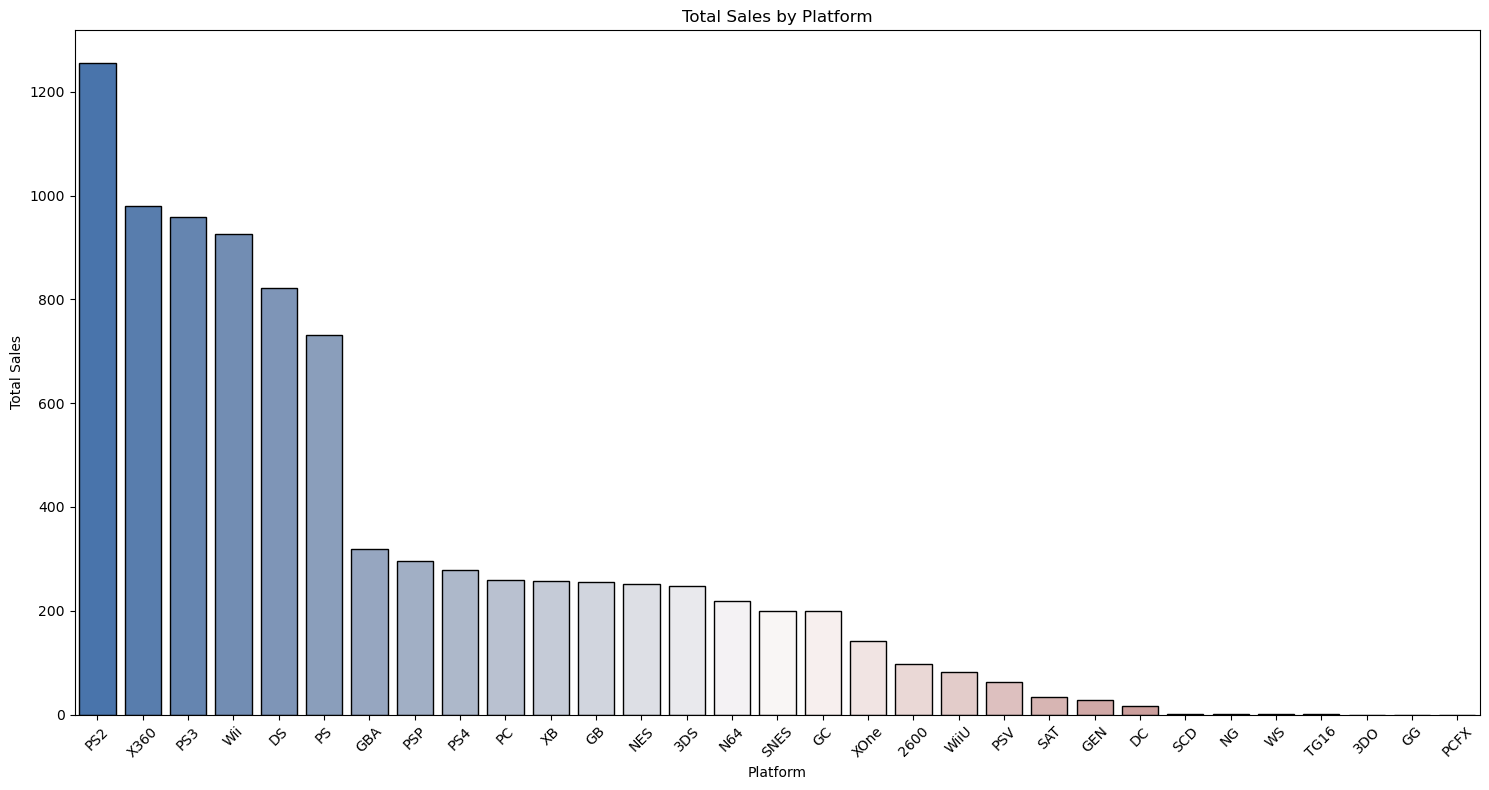

In [13]:
platform_sales = df.groupby("Platform")["Global_Sales"].sum().sort_values(ascending=False)
plt.figure(figsize=(15, 8))
sb.barplot(x=platform_sales.index,y=platform_sales.values,palette="vlag",edgecolor="black")
plt.xticks(rotation=45)
plt.title("Total Sales by Platform")
plt.ylabel("Total Sales")
plt.xlabel("Platform")
plt.tight_layout()
plt.show()

# Outcome

### 1. PS2 recorded the highest total global sales at 1,255.64 million copies, making it the best-selling platform in the dataset.
### 2. Xbox 360 ranked second with 979.96 million copies, while PS2 led by 275.68 million copies, highlighting its strong overall popularity

# Genre Analysis:

## *What are the most popular genres in terms of global sales revenue


C:\Users\Lokesh\AppData\Local\Temp\ipykernel_7764\3385188159.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.barplot(x=genre_sales.index,y=genre_sales.values,palette="vlag",edgecolor="black")


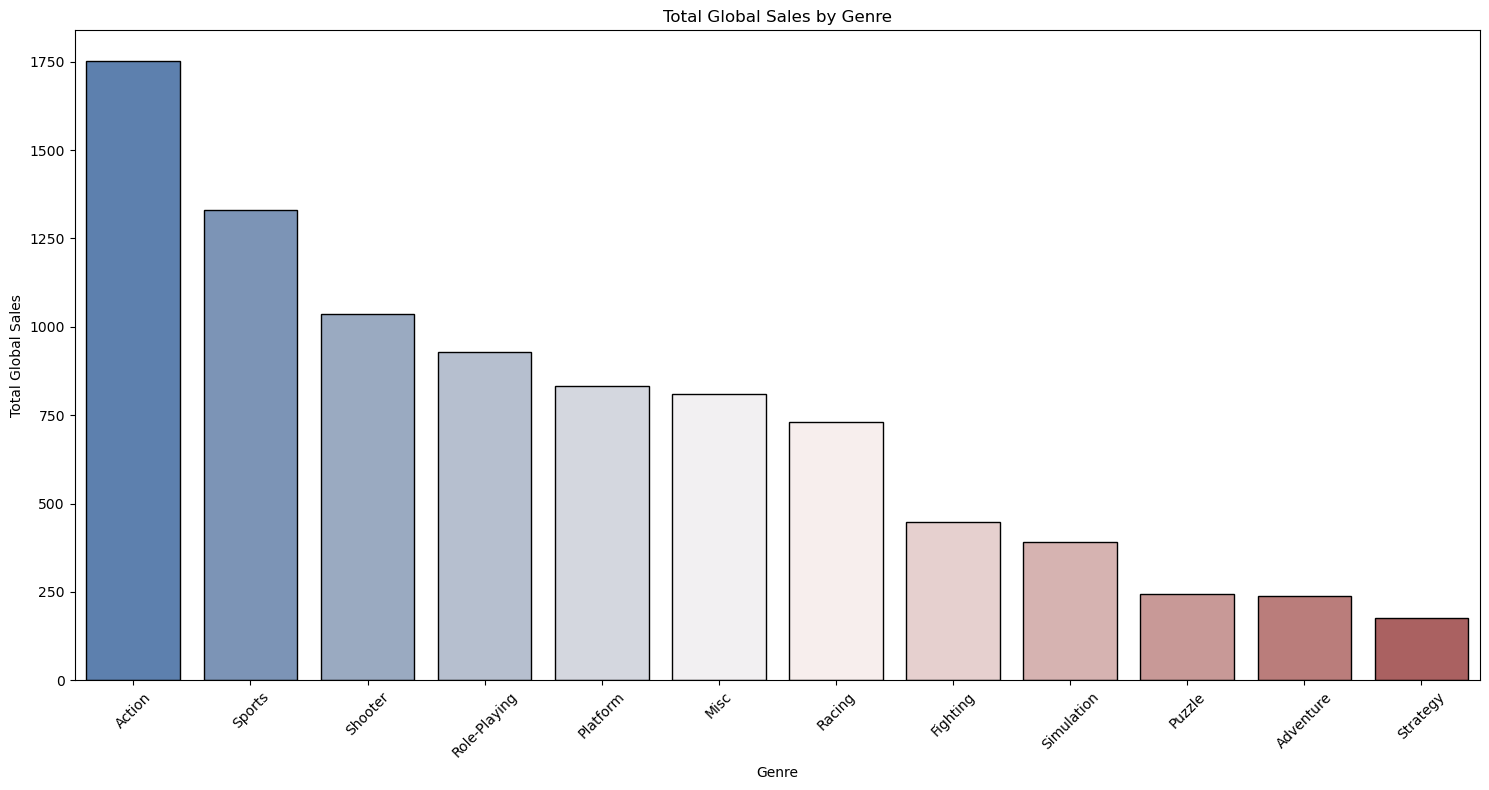

In [14]:
genre_sales = (df.groupby("Genre")["Global_Sales"].sum().sort_values(ascending=False))
plt.figure(figsize=(15, 8))
sb.barplot(x=genre_sales.index,y=genre_sales.values,palette="vlag",edgecolor="black")
plt.xticks(rotation=45)
plt.title("Total Global Sales by Genre")
plt.ylabel("Total Global Sales")
plt.xlabel("Genre")
plt.tight_layout()
plt.show()

# Outcome

### 1. Action games had the highest global sales at 1,751.18 million copies, followed by Sports games at 1,330.93 million, making these the two strongest genres in total sales.
### 2. Shooter games ranked third with 1,037.37 million copies sold, showing that Action, Sports, and Shooter games together accounted for a major share of overall game sales.

# * Can weidentify any emerging trends or shifts in genre preferences over time

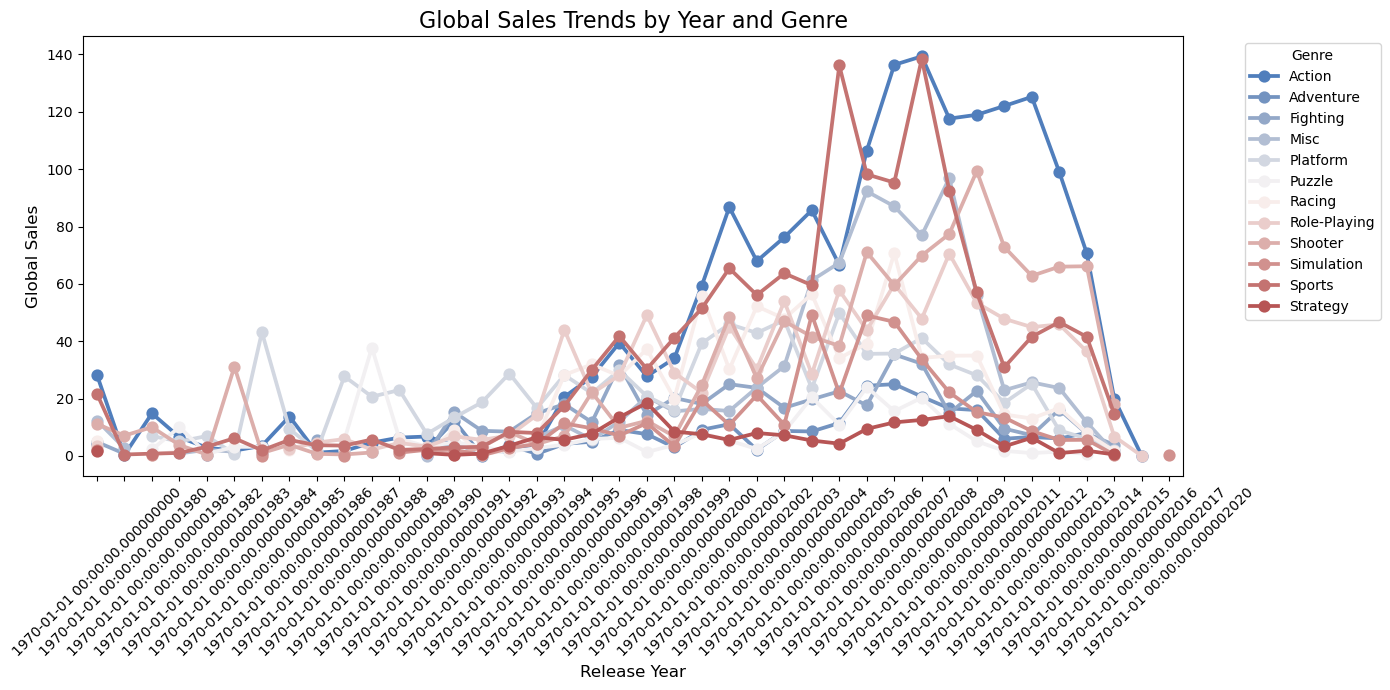

In [42]:
sales_by_year_genre = (df.dropna(subset=["Year", "Genre"]).groupby(["Year", "Genre"], as_index=False)["Global_Sales"].sum())
plt.figure(figsize=(14, 7))
sb.pointplot(data=sales_by_year_genre,x="Year",y="Global_Sales",hue="Genre",palette="vlag",markers="o",linestyles="-",errorbar=None)
plt.title("Global Sales Trends by Year and Genre", fontsize=16)
plt.xlabel("Release Year", fontsize=12)
plt.ylabel("Global Sales", fontsize=12)
plt.xticks(rotation=45)
plt.legend(title="Genre", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Outcome:

### 1. Action games dominated from 2007 to 2015, reaching their highest yearly sales of 139.36 million copies in 2009, showing strong demand during this period.
### 2. Sports games led in 2006 with 136.16 million copies sold, while Action games became the leading genre in most following years, indicating a shift in popularity toward Action games.

# Publisher Performance Analysis:

## * How does the performance of publishers vary in different regions

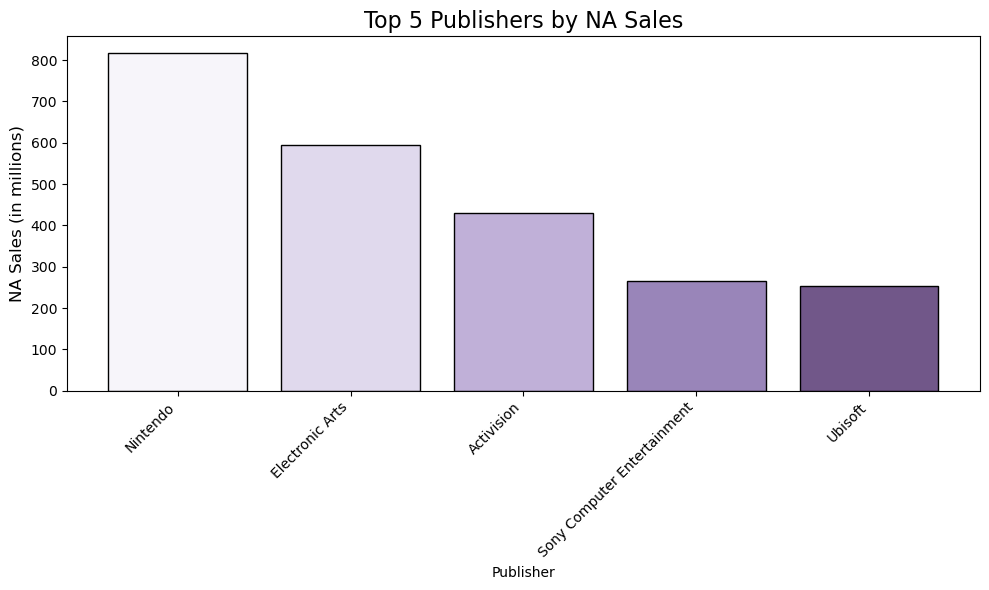

In [30]:
regional_sales = df.groupby("Publisher")[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]].sum()
NA=regional_sales.nlargest(5,"NA_Sales")
NA
top_5 = regional_sales.nlargest(5, "NA_Sales")
plt.figure(figsize=(10, 6))
plt.bar(top_5.index, top_5["NA_Sales"], color=sb.color_palette(["#F7F5FA", "#E0D9ED", "#C0B0D8", "#9985B9", "#715789"]), edgecolor="black", linewidth=1)
plt.title("Top 5 Publishers by NA Sales", fontsize=16,)
plt.xlabel("Publisher", fontsize=10)
plt.ylabel("NA Sales (in millions)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Outcome:

### 1. Nintendo ranked first in North America with 816.87 million copies sold, followed by Electronic Arts with 595.07 million copies.
### 2. Activision ranked third with 429.70 million copies, while Ubisoft recorded 253.43 million copies, highlighting Nintendo’s clear lead among the top five publishers in North America.

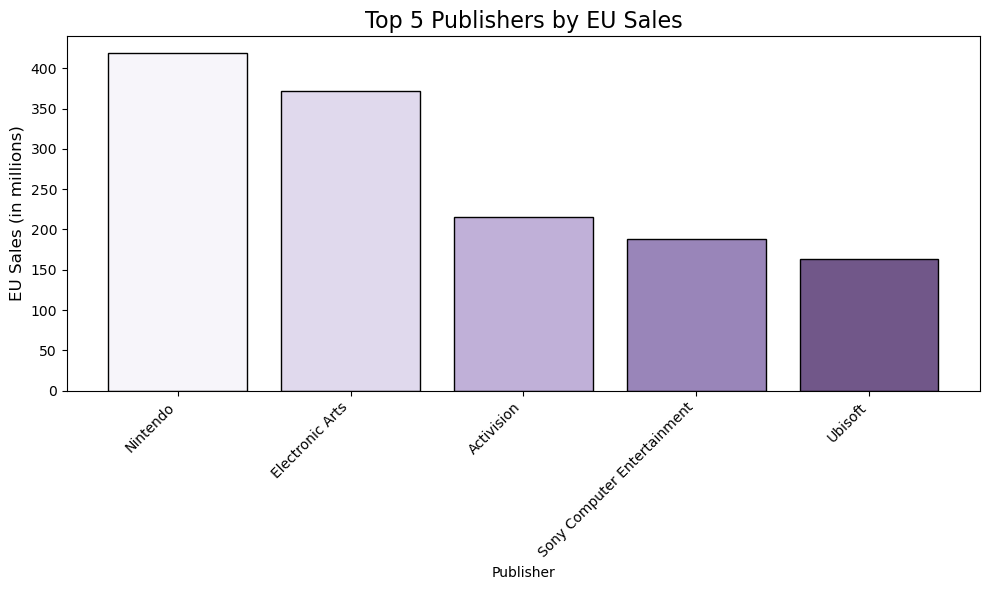

In [31]:
EU=regional_sales.nlargest(5,"EU_Sales")
EU
top_5 = regional_sales.nlargest(5, "EU_Sales")
plt.figure(figsize=(10, 6))
plt.bar(top_5.index, top_5["EU_Sales"], color=sb.color_palette(["#F7F5FA", "#E0D9ED", "#C0B0D8", "#9985B9", "#715789"]), edgecolor="black", linewidth=1)
plt.title("Top 5 Publishers by EU Sales", fontsize=16,)
plt.xlabel("Publisher", fontsize=10)
plt.ylabel("EU Sales (in millions)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Outcome:

### 1. Nintendo recorded the highest sales in Europe, with 418.74 million copies, followed by Electronic Arts with 361.44 million copies.
### 2. Activision ranked third with 215.53 million copies, showing that Nintendo maintained a clear lead over other major publishers in the European market.


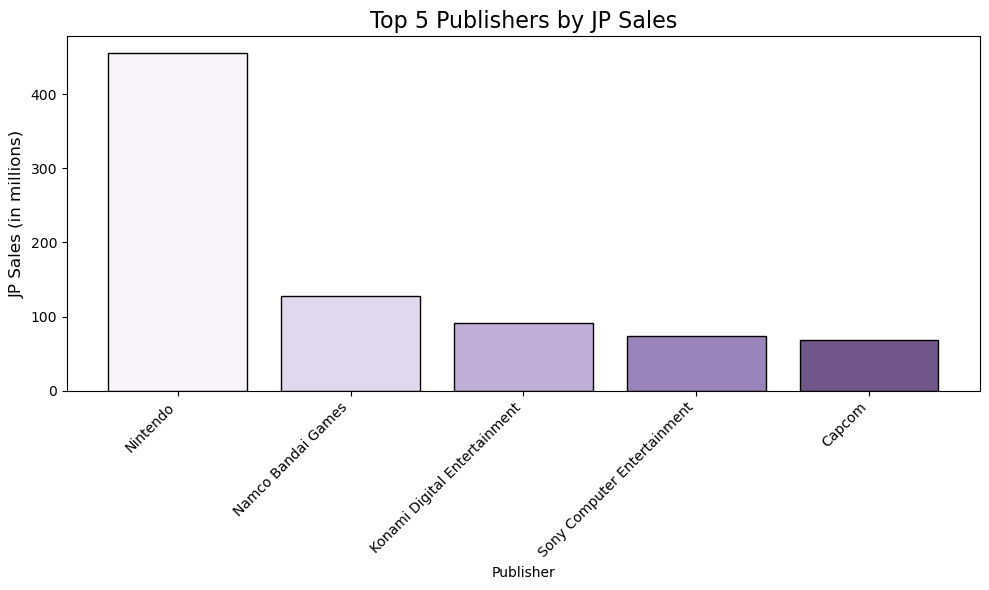

In [32]:
JP=regional_sales.nlargest(5,"JP_Sales")
JP
top_5 = regional_sales.nlargest(5, "JP_Sales")
plt.figure(figsize=(10, 6))
plt.bar(top_5.index, top_5["JP_Sales"], color=sb.color_palette(["#F7F5FA", "#E0D9ED", "#C0B0D8", "#9985B9", "#715789"]), edgecolor="black", linewidth=1)
plt.title("Top 5 Publishers by JP Sales", fontsize=16,)
plt.xlabel("Publisher", fontsize=10)
plt.ylabel("JP Sales (in millions)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Outcome:

### 1. Nintendo dominated the Japanese market, recording approximately 455.42 million copies sold, making it the leading publisher in Japan.
### 2. Namco Bandai Games ranked second with around 127.07 million copies, highlighting the strong presence of Japanese publishers in their home market.

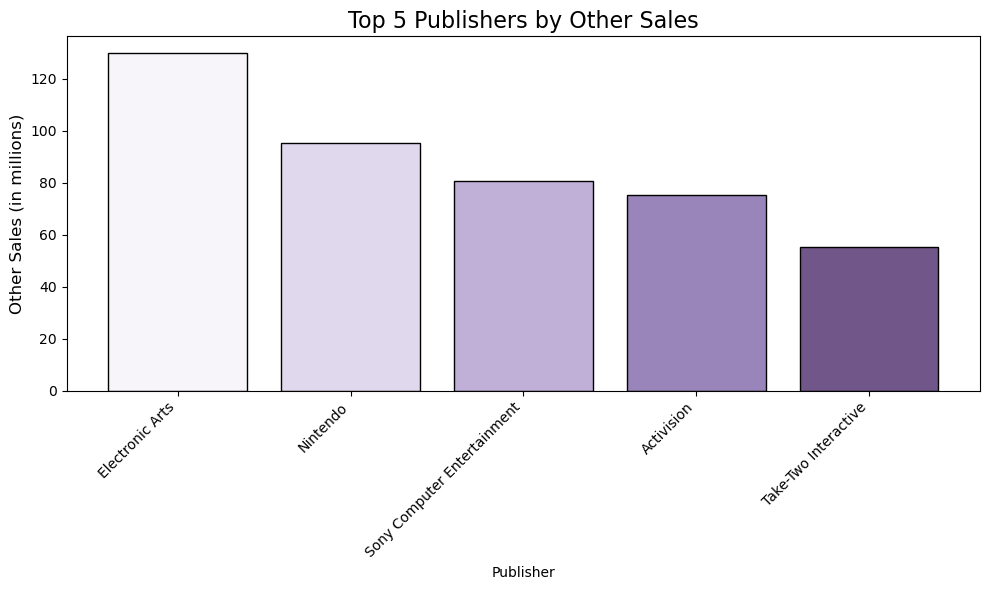

In [33]:
Other_Sales=regional_sales.nlargest(5,"Other_Sales")
Other_Sales
top_5 = regional_sales.nlargest(5, "Other_Sales")
plt.figure(figsize=(10, 6))
plt.bar(top_5.index, top_5["Other_Sales"], color=sb.color_palette(["#F7F5FA", "#E0D9ED", "#C0B0D8", "#9985B9", "#715789"]), edgecolor="black", linewidth=1)
plt.title("Top 5 Publishers by Other Sales", fontsize=16,)
plt.xlabel("Publisher", fontsize=10)
plt.ylabel("Other Sales (in millions)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Outcome:

### 1. Nintendo recorded the highest sales in the Other region, with approximately 95.66 million copies, showing its strong reach beyond North America, Europe, and Japan.
### 2. Electronic Arts ranked second with around 129.77 million copies—please verify the publisher ranking and values from your chart, as these figures may not be in the correct order.


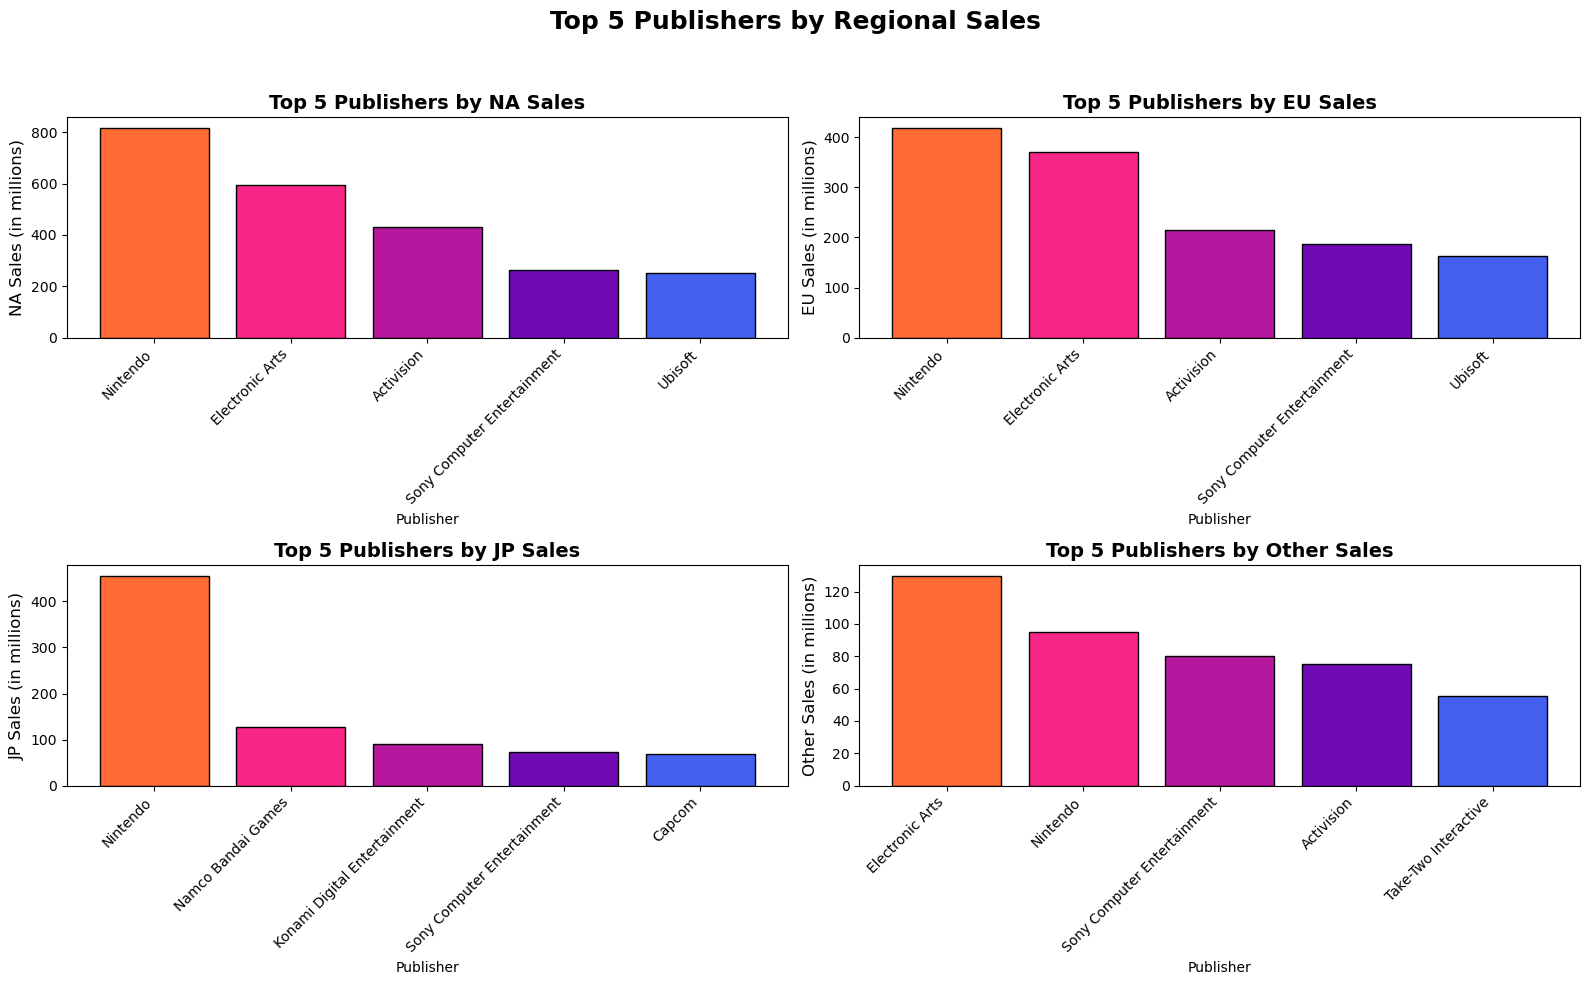

In [40]:


plt.figure(figsize=(16, 10))
sunset = ["#FF6B35", "#F72585", "#B5179E", "#7209B7", "#4361EE", "#FFB703"]
regional_sales = df.groupby("Publisher")[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]].sum()

plt.subplot(2, 2, 1)
top_5 = regional_sales.nlargest(5, "NA_Sales")
plt.bar(top_5.index, top_5["NA_Sales"],color=sunset[:5], edgecolor="black", linewidth=1)
plt.title("Top 5 Publishers by NA Sales", fontsize=14, fontweight="bold")
plt.xlabel("Publisher", fontsize=10)
plt.ylabel("NA Sales (in millions)", fontsize=12)
plt.xticks(rotation=45, ha="right")

plt.subplot(2, 2, 2)
top_5 = regional_sales.nlargest(5, "EU_Sales")
plt.bar(top_5.index, top_5["EU_Sales"],color=sunset[:5], edgecolor="black", linewidth=1)
plt.title("Top 5 Publishers by EU Sales", fontsize=14, fontweight="bold")
plt.xlabel("Publisher", fontsize=10)
plt.ylabel("EU Sales (in millions)", fontsize=12)
plt.xticks(rotation=45, ha="right")

plt.subplot(2, 2, 3)
top_5 = regional_sales.nlargest(5, "JP_Sales")
plt.bar(top_5.index, top_5["JP_Sales"],color=sunset[:5], edgecolor="black", linewidth=1)
plt.title("Top 5 Publishers by JP Sales", fontsize=14, fontweight="bold")
plt.xlabel("Publisher", fontsize=10)
plt.ylabel("JP Sales (in millions)", fontsize=12)
plt.xticks(rotation=45, ha="right")

plt.subplot(2, 2, 4)
top_5 = regional_sales.nlargest(5, "Other_Sales")
plt.bar(top_5.index, top_5["Other_Sales"],color=sunset[:5], edgecolor="black", linewidth=1)
plt.title("Top 5 Publishers by Other Sales", fontsize=14, fontweight="bold")
plt.xlabel("Publisher", fontsize=10)
plt.ylabel("Other Sales (in millions)", fontsize=12)
plt.xticks(rotation=45, ha="right")

plt.suptitle("Top 5 Publishers by Regional Sales",fontsize=18, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### *Nintendo leads publisher sales across regions, with 816.87 million in North America, 418.74 million in Europe, and 455.42 million in Japan. Electronic Arts also performs strongly, recording 595.07 million in North America and 361.44 million in Europe.
### *In Japan, Namco Bandai Games achieved 127.07 million in sales.Overall, Nintendo shows strong international performance, while publisher sales vary across regions.¶

# Regional Sales Analysis:

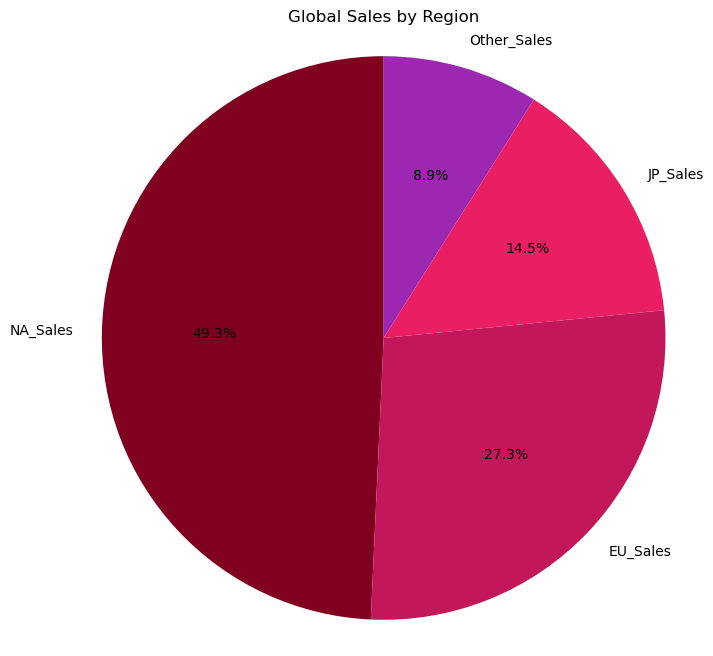

In [36]:
regional_sales=df[["NA_Sales","EU_Sales","JP_Sales","Other_Sales"]].sum()
regional_sales.nlargest(5)
multi_cherry= ["#800020", "#C2185B", "#E91E63", "#9C27B0", "FF5252", "#FF8A65"]
colors = sb.color_palette(multi_cherry, n_colors=len(regional_sales)).as_hex()
plt.figure(figsize=(8, 8))
plt.pie(regional_sales.to_numpy(),labels=regional_sales.index,colors=colors,autopct="%1.1f%%", startangle=90)
plt.title("Global Sales by Region")
plt.axis("equal")
plt.show()

# Outcome:

### 1. North America leads global video game sales with 4,392.95 million units (52.9%), followed by Europe with 2,434.13 million units (29.3%).
### 2. North America and Europe together contribute approximately 82.2% of global sales, while Japan and Other regions account for the remaining share.¶

# * How do sales revenues vary across different regions (e.g., North America, Europe, Japan, Other

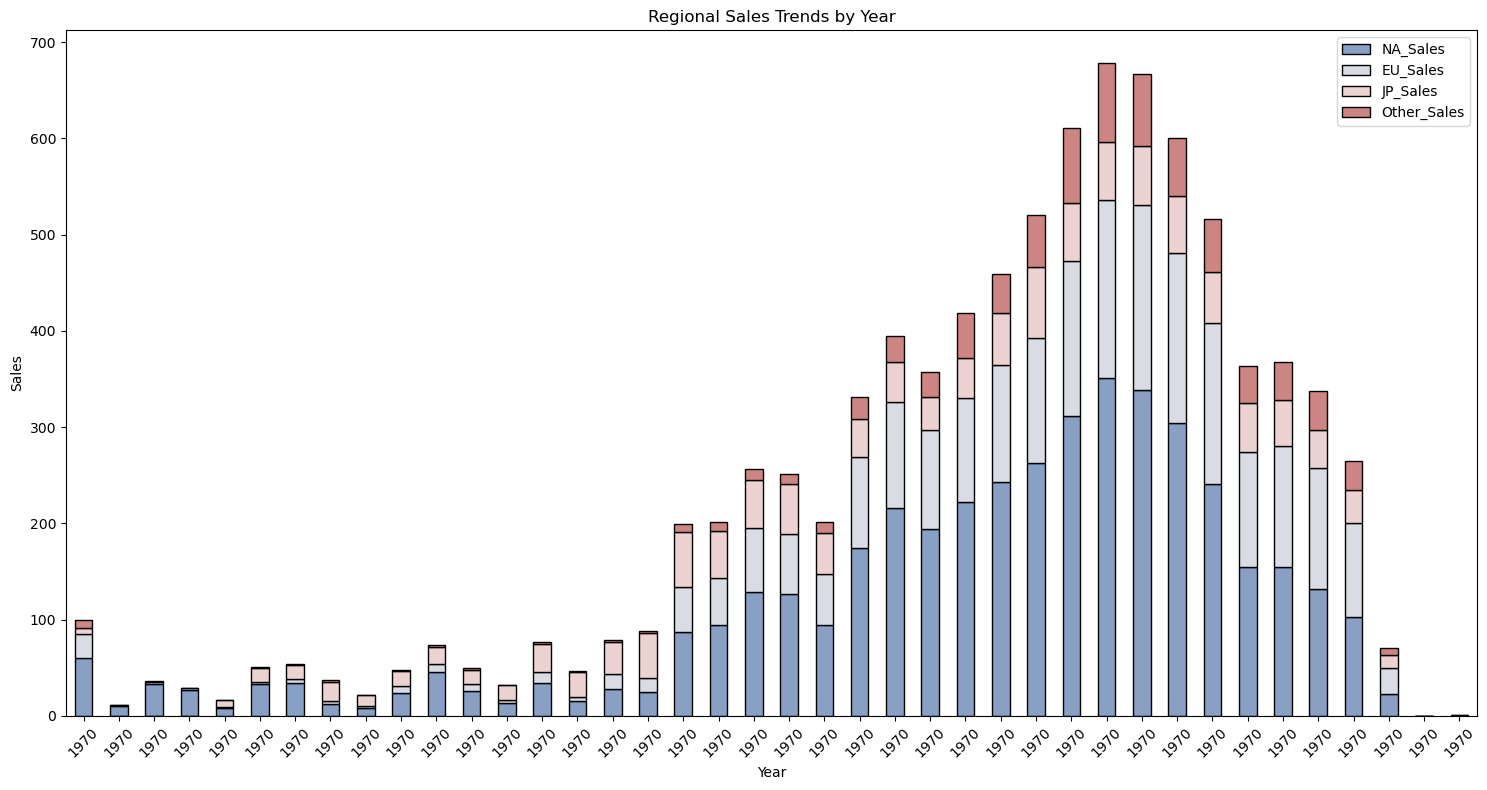

In [23]:
sales_by_year = (df.dropna(subset=["Year"]).groupby("Year")[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]].sum())
sales_by_year.index = pd.to_datetime(sales_by_year.index).year.astype(str)
sales_by_year.plot(kind="bar",stacked=True,figsize=(15, 8),color=sb.color_palette("vlag", n_colors=4),edgecolor="black")
plt.title("Regional Sales Trends by Year")
plt.xlabel("Year")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Outcome:

### 1. 2008 recorded the highest total sales at 678.49 million units, including North America (351.44 million), Europe (184.40 million), Japan (60.26 million), and Other regions (82.39 million).
### 2. 2009 ranked second, with total sales of 667.10 million units. North America and Europe were the largest contributors, showing their strong influence on yearly global video game sales.


# * Can we identify any regional preferences or trends in gaming preferences

<Figure size 1500x3000 with 0 Axes>

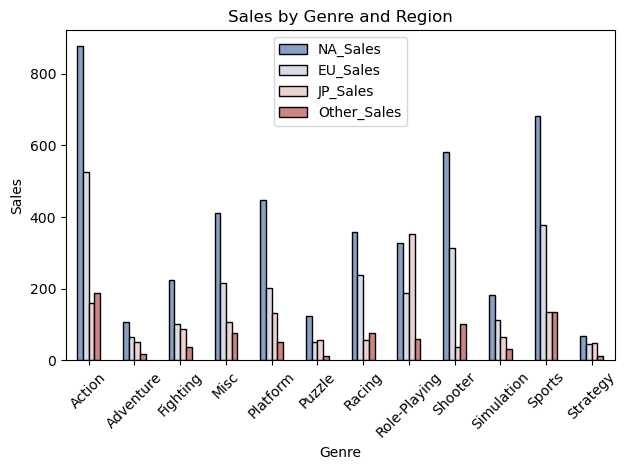

In [24]:
rs = df.groupby("Genre")[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]].sum()
plt.figure(figsize=(15, 30))
rs.plot(kind="bar",color=sb.color_palette("vlag", n_colors=4),edgecolor="black") 
plt.title("Sales by Genre and Region")
plt.xlabel("Genre")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Outcome:

### 1. Action genre has the highest total global sales at 1,751.18 million units, followed by Sports at 1,330.93 million and Shooter at 1,037.37 million.
### 2. North America contributes the largest share for many genres, while Japan shows comparatively stronger sales in Role-Playing games, with 352.31 million units. Overall, Action, Sports, and Shooter are the leading genres across regions.